# 26 Does the precursor's spectrum add anything, and is there a compact law?

The project's question is whether a precursor's properties tell a merger from a collapsar. Zhu et al.'s EPI uses the precursor's timing and the main emission's E_peak. Here I test, on our own measurements with their errors, whether the precursor's own E_peak adds anything, and then whether a shorter law than EPI does as well.

Two kinds of label are kept apart (`laws.label_table`):

- confirmed: an associated kilonova (GRB 211211A, 230307A) or supernova (090618, 111228A, 180728A, 190114C, 190829A, 211023A);
- candidate: Zhu et al.'s types, which come from clustering numbers that most of the laws below also use (notebook 22). The three short bursts in old hosts are candidates too, since they are only "generally considered" mergers.

Only candidate labels are numerous enough to fit anything, so everything fitted here is a statement about reproducing their classification, not about true origins. The confirmed bursts are a check on the result, never used to fit it. Every score is cross-validated: the model or law is chosen on some bursts and scored on bursts it hasn't seen.

1. The labels
2. Does E_p,PE add to EPI?
3. Which of EPI's terms matter
4. A compact law
5. Each burst's chance under the laws
6. The confirmed bursts
7. What the laws mean physically
8. What this says

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from zhu import RESULTS
from zhu import laws as L
from zhu.catalogue import EPI_LINE, epi, read_table_2026
from zhu.features import collect, epi_summary, input_draws

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
FIGURES = Path("figures")
COLOURS = {"I-S": "#2a78d6", "I-L": "#eb6834", "II": "0.6"}

table = read_table_2026()
by_mode = {mode: collect(mode) for mode in ("zhu2026", "zhu2025", "project")}
ours = by_mode["zhu2026"]
labels = L.label_table(ours.index, table.Type)
ours = ours.join(labels).join(epi_summary(ours, way="zhu"))
X = L.inputs(ours)
X["EPI"] = ours.EPI_zhu
X["ratio"] = X.Ep_PE - X.Ep_ME
y = ours.candidate_merger
print(len(ours), "bursts;", labels.label_status.value_counts().to_dict(), "; candidate mergers:", int(y.sum()))
print("precursor E_peak measured by our rule for", int(X.Ep_PE.notna().sum()), "bursts")

110 bursts; {'candidate': 103, 'confirmed': 7} ; candidate mergers: 43
precursor E_peak measured by our rule for 71 bursts


## 1. The labels

In [2]:
confirmed = ours[ours.label_status == "confirmed"]
confirmed[["confirmed", "zhu_type", "EPI_zhu", "EPI_p16_zhu", "EPI_p84_zhu", "P_above_zhu"]].round(2)

,confirmed,zhu_type,EPI_zhu,EPI_p16_zhu,EPI_p84_zhu,P_above_zhu
name,,,,,,
090618A,collapsar,II,1.09,0.85,1.44,0.00
180728A,collapsar,II,1.97,1.90,2.83,0.00
190114C,collapsar,II,5.07,4.87,5.64,0.08
190829A,collapsar,II,-0.19,-0.60,-0.02,0.00
211023A,collapsar,II,0.45,0.10,0.82,0.00
211211A,merger,I-L,7.97,7.79,8.31,1.00
230307A,merger,I-L,NaN,NaN,NaN,NaN


Seven bursts of the sample have a confirmed origin: GRB 211211A and 230307A were followed by a kilonova, and GRB 090618, 180728A,
190114C, 190829A and 211023A by a supernova (GRB 111228A, the eighth, can't be measured). Everything else carries Zhu et al.'s type, a
candidate label from their clustering. With our numbers EPI puts GRB 211211A far above the line (7.97, chance 1.00) and the supernova
collapsars below it, 190114C nearest (5.07, chance 0.08) and 190829A lowest (-0.19, its main emission peaking at the bottom of
GBM's band; notebook 24). GRB 230307A has no EPI of ours because the rule finds no precursor (notebook 23).

### The three populations

Confirmed mergers have a kilonova, confirmed collapsars a supernova. Merger candidates are Zhu et al.'s Type I-S and I-L bursts without a kilonova (Tan et al.'s three Type IL candidates are among them); they are never treated as confirmed. The rest are Zhu et al.'s Type II without a supernova. Filled markers: precursor E_p measured by our rule. Not measured: a vertical line for a 95% interval bounded both ways, or an open marker at its one bound with an arrow pointing to the open side (a bound beyond the plotted 5 keV-30 MeV is drawn near the edge). The right panel needs both E_peak measured. GRB 230307A has no precursor under the zhu2026 rule as written (notebook 23: the block that is their gap is 4.2 sigma per bin above our background, against the 3.15 they state), so its precursor is the one measured in notebook 12 on Dichiara et al.'s window, drawn apart (open star) with EPI from their table; it stays out of the classification tests and enters only the planning estimate of section 6. The legend counts the bursts drawn, which need an EPI of ours (GRB 130804A's main emission can't be fitted their way, so it has none); the table below counts every burst.


GRB 230307A (notebook 12's precursor window, -0.064 to 0.32 s): E_p,PE 170.3 keV, E_p,PE / E_p,ME 0.188 (E_p,ME ours, 908 keV), EPI from their table 8.47


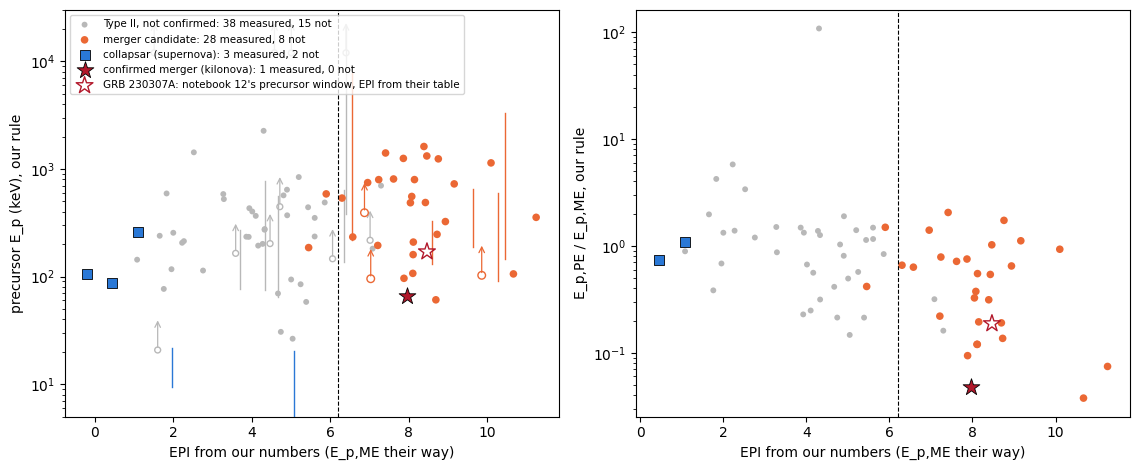

,bursts,precursor E_p measured,"median E_p,PE (keV)","median E_p,PE/E_p,ME"
population,,,,
confirmed merger (kilonova),2,1,65.94,0.05
collapsar (supernova),5,3,105.55,0.91
merger candidate,41,29,487.73,0.55
"Type II, not confirmed",62,38,247.32,0.96


In [3]:
from zhu.laws import CONFIRMED
pop = pd.Series("Type II, not confirmed", index=ours.index)
pop[ours.zhu_type.astype(str).str.startswith("I-")] = "merger candidate"
pop[[n for n, o in CONFIRMED.items() if o == "merger" and n in pop.index]] = "confirmed merger (kilonova)"
pop[[n for n, o in CONFIRMED.items() if o == "collapsar" and n in pop.index]] = "collapsar (supernova)"
ours["population"] = pop
kn_230307A = None
if "230307A" in ours.index and str(ours.measured_PE.get("230307A")) != "True":
    pre = pd.read_csv("shared/epeak_230307A.csv", comment="#").set_index("label").loc["pre"]
    t = table.loc["230307A"]
    kn_230307A = dict(EPI=float(epi(t.Ep_ME, t.T100_PE, t.T100_QE1, t.TMVT_PE)), Ep_PE=float(pre.Epeak_keV),
                 ratio=float(pre.Epeak_keV) / ours.Ep_ME_ours["230307A"])
    print(f"GRB 230307A (notebook 12's precursor window, -0.064 to 0.32 s): E_p,PE {kn_230307A['Ep_PE']:.1f} keV, E_p,PE / E_p,ME "
          f"{kn_230307A['ratio']:.3f} (E_p,ME ours, {ours.Ep_ME_ours['230307A']:.0f} keV), EPI from their table {kn_230307A['EPI']:.2f}")
style = {"Type II, not confirmed": ("0.72", "o", 18, 1), "merger candidate": ("#eb6834", "o", 30, 2),
         "collapsar (supernova)": ("#2a78d6", "s", 60, 3), "confirmed merger (kilonova)": ("#b2182b", "*", 160, 4)}
measured = ours.measured_PE.astype(str) == "True"
both = measured & (ours.measured_ME.astype(str) == "True")      # a ratio needs both E_peak measured (GRB 190829A's E_p,ME isn't)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
for name, (colour, marker, size, z) in style.items():
    d = ours[(ours.population == name) & ours.EPI_zhu.notna()]       # only a burst with an EPI of ours can be drawn
    m = d[measured[d.index]]
    edge = "k" if name in ("confirmed merger (kilonova)", "collapsar (supernova)") else "none"
    label = f"{name}: {len(m)} measured, {len(d) - len(m)} not"
    axes[0].scatter(m.EPI_zhu, m.Ep_PE_ours, c=colour, marker=marker, s=size, edgecolors=edge, linewidths=0.6, zorder=z, label=label)
    mb = d[both[d.index]]
    axes[1].scatter(mb.EPI_zhu, mb.Ep_PE_ours / mb.Ep_ME_ours, c=colour, marker=marker, s=size, edgecolors=edge, linewidths=0.6, zorder=z)
    lim = d[~measured[d.index] & (d.Ep_PE_cpl_limit_lo.notna() | d.Ep_PE_cpl_limit_hi.notna())]
    # E_p is plotted from 5 keV to 30 MeV; a bound beyond that is drawn near the edge (leaving room for its arrow), pointing the open way
    for x, lo, hi in zip(lim.EPI_zhu, lim.Ep_PE_cpl_limit_lo.clip(upper=1.2e4), lim.Ep_PE_cpl_limit_hi.clip(lower=12.0)):
        if pd.notna(lo) and pd.notna(hi):
            axes[0].plot([x, x], [lo, hi], color=colour, lw=1.0, zorder=z)
        elif pd.notna(hi):
            axes[0].annotate("", xy=(x, hi / 2), xytext=(x, hi), arrowprops=dict(arrowstyle="->", color=colour, lw=0.9), zorder=z)
            axes[0].scatter([x], [hi], facecolors="none", edgecolors=colour, marker=marker, s=size, zorder=z)
        else:
            axes[0].annotate("", xy=(x, lo * 2), xytext=(x, lo), arrowprops=dict(arrowstyle="->", color=colour, lw=0.9), zorder=z)
            axes[0].scatter([x], [lo], facecolors="none", edgecolors=colour, marker=marker, s=size, zorder=z)
if kn_230307A is not None:
    for ax, value in ((axes[0], kn_230307A["Ep_PE"]), (axes[1], kn_230307A["ratio"])):
        ax.scatter([kn_230307A["EPI"]], [value], marker="*", s=160, facecolors="none", edgecolors="#b2182b", linewidths=1.0, zorder=5,
                   label="GRB 230307A: notebook 12's precursor window, EPI from their table" if ax is axes[0] else None)
axes[0].set_ylim(5, 3e4)
for ax, ylabel in ((axes[0], "precursor E_p (keV), our rule"), (axes[1], "E_p,PE / E_p,ME, our rule")):
    ax.set_yscale("log")
    ax.axvline(EPI_LINE, color="k", ls="--", lw=0.8)
    ax.set_xlabel("EPI from our numbers (E_p,ME their way)")
    ax.set_ylabel(ylabel)
axes[0].legend(fontsize=7.5, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "26_three_populations.png", dpi=150)
plt.show()

d = ours.assign(ratio=ours.Ep_PE_ours / ours.Ep_ME_ours, measured=measured, both=both)
by = d.groupby("population")
table3 = pd.DataFrame({"bursts": by.size(), "precursor E_p measured": by.measured.sum(),
                       "median E_p,PE (keV)": d[d.measured].groupby("population").Ep_PE_ours.median(),
                       "median E_p,PE/E_p,ME": d[d.both].groupby("population").ratio.median()})
table3.loc[list(style)[::-1]].round(2)


Kept apart: two confirmed long mergers, five supernova collapsars, 41 merger candidates and 62 Type II bursts without a supernova. The
two confirmed mergers have precursors far softer than their main emission: GRB 211211A's E_p,PE/E_p,ME is 0.05 (66 keV against
about 1370 keV from the two-break model; 0.10 with the main emission fitted their way), and GRB 230307A's, from notebook 12's window,
0.19. The candidates' median is 0.55, the supernova collapsars' 0.91 and Type II's 0.96 (a ratio is only computed where both E_peak
are measured). GRB 190829A, a supernova collapsar, goes the other way: its precursor (105 keV) is harder than its main emission, whose
peak lies below GBM's band, so its ratio is only a lower limit of about 10. So the confirmed mergers sit at the soft end,
but the candidates spread over the whole range, and two bursts can't show that confirmed mergers differ (the power estimate in
section 6).


## 2. Does E_p,PE add to EPI?

On the bursts whose precursor and main-emission E_peak our rule both count as measured (the ratio needs both), logistic models with EPI alone, EPI with log E_p,PE, and EPI with log(E_p,PE / E_p,ME), and the same with the precursor's timing in place of EPI. Each is scored on the folds it wasn't fitted to (5 folds, 20 repeats, classes weighted by size): area under the ROC curve, balanced accuracy, average precision (the precision-recall area, which watches the rarer class) and log loss (lower is better). Then a permutation test: E_p,PE is shuffled among the bursts 200 times, and the share of shuffles that improve the log loss as much as the real E_p,PE is the p-value.

In [4]:
measured = X.dropna(subset=["EPI", "Ep_PE", "Ep_ME", "T_PE", "T_QE1", "MVT_PE"])
measured = measured[(ours.measured_ME.astype(str) == "True")[measured.index]]      # the ratio needs both E_peak measured
y_m = y[measured.index]
print(len(measured), "bursts:", int(y_m.sum()), "candidate mergers,", int((~y_m).sum()), "candidate collapsars")
sets = {"EPI": ["EPI"], "EPI + E_p,PE": ["EPI", "Ep_PE"], "EPI + E_p,PE/E_p,ME": ["EPI", "ratio"],
        "precursor timing": ["T_PE", "T_QE1", "MVT_PE"], "precursor timing + E_p,PE": ["T_PE", "T_QE1", "MVT_PE", "Ep_PE"], "E_p,PE alone": ["Ep_PE"]}
summary, fold_scores = L.compare_feature_sets(measured, y_m, sets)
print(summary[["auc_mean", "auc_spread", "balanced_accuracy_mean", "average_precision_mean", "log_loss_mean", "log_loss_vs_first", "better_than_first"]].round(3).to_string())
for base, extra in ((["EPI"], "Ep_PE"), (["EPI"], "ratio"), (["T_PE", "T_QE1", "MVT_PE"], "Ep_PE")):
    gain, gains, p = L.permutation_test(measured, y_m, base, extra)
    print(f"adding {extra} to {base}: gain in log loss {gain:+.4f}, permutation p = {p:.3f}")
value, ci68, ci95 = L.bootstrap_auc(measured.Ep_PE, y_m)
print(f"E_p,PE alone: area {value:.3f} (68% {ci68[0]:.2f}-{ci68[1]:.2f}, 95% {ci95[0]:.2f}-{ci95[1]:.2f}); above 0.5 means higher in candidate mergers")

69 bursts: 29 candidate mergers, 40 candidate collapsars


                           auc_mean  auc_spread  balanced_accuracy_mean  average_precision_mean  log_loss_mean  log_loss_vs_first  better_than_first
features                                                                                                                                            
EPI                           0.986       0.024                   0.939                   0.982          0.216              0.000               0.00
EPI + E_p,PE                  0.983       0.029                   0.940                   0.979          0.217              0.002               0.61
EPI + E_p,PE/E_p,ME           0.982       0.030                   0.939                   0.978          0.223              0.007               0.05
precursor timing              0.954       0.057                   0.867                   0.945          0.288              0.072               0.17
precursor timing + E_p,PE     0.963       0.050                   0.901                   0.952          0

adding Ep_PE to ['EPI']: gain in log loss -0.0051, permutation p = 0.537


adding ratio to ['EPI']: gain in log loss -0.0074, permutation p = 0.697


adding Ep_PE to ['T_PE', 'T_QE1', 'MVT_PE']: gain in log loss +0.0109, permutation p = 0.060


E_p,PE alone: area 0.636 (68% 0.56-0.70, 95% 0.49-0.77); above 0.5 means higher in candidate mergers


The precursors our rule doesn't count as measured have a 95% interval instead. Putting each at the bottom, the middle (in log) or the top of its interval shows whether leaving them out changes the answer.

In [5]:
limits = ours[(ours.measured_PE.astype(str) != "True") & ours.Ep_PE_cpl_limit_lo.notna()]
print(len(limits), "precursors with a 95% interval only;", int(limits.candidate_merger.sum()), "of them candidate mergers")
rows = []
for where in ("low", "middle", "high"):
    filled = X.copy()
    lo, hi = np.log10(limits.Ep_PE_cpl_limit_lo.clip(lower=1)), np.log10(limits.Ep_PE_cpl_limit_hi.fillna(2e4).clip(upper=2e4))
    filled.loc[limits.index, "Ep_PE"] = {"low": lo, "middle": 0.5 * (lo + hi), "high": hi}[where]
    filled["ratio"] = filled.Ep_PE - filled.Ep_ME
    use = filled.dropna(subset=["EPI", "Ep_PE"])
    use = use[(ours.measured_ME.astype(str) == "True")[use.index]]
    s, _ = L.compare_feature_sets(use, y[use.index], {"EPI": ["EPI"], "EPI + E_p,PE": ["EPI", "Ep_PE"]}, repeats=10)
    rows.append(dict(limits_at=where, bursts=len(use), auc_EPI=s.auc_mean["EPI"], auc_with_Ep_PE=s.auc_mean["EPI + E_p,PE"],
                     log_loss_change=s.log_loss_vs_first["EPI + E_p,PE"], area_Ep_PE_alone=L.auc(use.Ep_PE, y[use.index])))
pd.DataFrame(rows).round(3)

25 precursors with a 95% interval only; 8 of them candidate mergers


,limits_at,bursts,auc_EPI,auc_with_Ep_PE,log_loss_change,area_Ep_PE_alone
0,low,93,0.986,0.979,0.018,0.575
1,middle,93,0.986,0.984,0.010,0.574
2,high,93,0.986,0.984,0.007,0.578


E_p,PE improves the precursor's timing alone but not EPI. EPI already holds E_p,ME, so if a hard precursor simply goes with a hard main emission, E_p,PE should add nothing once E_p,ME is in the model. Tested with EPI's four inputs as separate columns, so that the weights are free.


In [6]:
from scipy.stats import spearmanr
rho, p = spearmanr(measured.Ep_PE, measured.Ep_ME)
print(f"log E_p,PE against log E_p,ME: Spearman rho {rho:.2f} (p = {p:.1g}), {len(measured)} bursts")
for flag, name in ((True, "candidate mergers"), (False, "candidate collapsars")):
    d = measured[y_m == flag]
    r, q = spearmanr(d.Ep_PE, d.Ep_ME)
    print(f"   within the {name}: rho {r:.2f} (p = {q:.2g}), {len(d)} bursts")
four = ["T_PE", "T_QE1", "MVT_PE", "Ep_ME"]
for base, extra in ((["Ep_ME"], "Ep_PE"), (four, "Ep_PE"), (four, "ratio")):
    gain, gains, p = L.permutation_test(measured, y_m, base, extra)
    print(f"adding {extra} to {base}: gain in log loss {gain:+.4f}, permutation p = {p:.3f}")


log E_p,PE against log E_p,ME: Spearman rho 0.41 (p = 0.0005), 69 bursts
   within the candidate mergers: rho 0.27 (p = 0.16), 29 bursts
   within the candidate collapsars: rho 0.39 (p = 0.012), 40 bursts


adding Ep_PE to ['Ep_ME']: gain in log loss -0.0133, permutation p = 0.726


adding Ep_PE to ['T_PE', 'T_QE1', 'MVT_PE', 'Ep_ME']: gain in log loss -0.0017, permutation p = 0.303


adding ratio to ['T_PE', 'T_QE1', 'MVT_PE', 'Ep_ME']: gain in log loss -0.0061, permutation p = 0.577


On the 69 bursts with every number, EPI alone separates their types with an out-of-sample area of 0.986. Adding the precursor's E_peak
or its ratio to the main emission doesn't improve the log loss (0.217 and 0.223 against 0.216), and a shuffled copy of either does as
well (permutation p = 0.54 and 0.70). Putting the 24 precursors that have only a 95% interval (those in bursts whose E_p,ME is measured; 25 in all) at either end of
it changes nothing. Even on the precursor's
timing alone, E_p,PE adds little (p = 0.06), and what it does add is the main emission's E_peak in disguise: log E_p,PE follows log
E_p,ME (Spearman 0.41, p = 5e-4), adding it to E_p,ME alone gives nothing (p = 0.73), and adding it or the ratio to all four of EPI's
inputs gives nothing either (p = 0.30 and 0.58).

**Measured:** the precursor's spectrum carries no information about their type beyond what EPI holds. **Interpretation:** a hard
precursor goes with a hard burst, and EPI already has the burst's hardness through E_p,ME.

## 3. Which of EPI's terms matter

EPI is 2 log E_p,ME - log T100,PE - 0.5 log T100,QE1 - log T_MVT,PE. With the four logs as separate columns of a logistic model, I drop each in turn (all bursts with the four numbers, our measurements).

In [7]:
terms = ["Ep_ME", "T_PE", "T_QE1", "MVT_PE"]
use = X.dropna(subset=terms)
sets = {"all four": terms, **{f"without {t}": [u for u in terms if u != t] for t in terms}}
ablation, _ = L.compare_feature_sets(use, y[use.index], sets)
print(len(use), "bursts")
ablation[["auc_mean", "balanced_accuracy_mean", "average_precision_mean", "log_loss_mean", "log_loss_vs_first"]].round(3)

95 bursts


,auc_mean,balanced_accuracy_mean,average_precision_mean,log_loss_mean,log_loss_vs_first
features,,,,,
all four,0.981,0.914,0.973,0.201,0.000
without Ep_ME,0.942,0.841,0.926,0.306,0.104
without T_PE,0.967,0.876,0.957,0.265,0.064
without T_QE1,0.966,0.919,0.945,0.245,0.044
without MVT_PE,0.978,0.918,0.966,0.207,0.005


With the four logs as free columns, the main emission's E_peak matters most (dropping it raises the log loss by 0.104), then the
precursor's duration (0.064) and the gap (0.044), and last T_MVT,PE (0.005). In our measurements the precursor's MVT adds almost
nothing, which fits the 0.4 dex of counting noise in its brightest-bin reading (notebook 23).

## 4. A compact law

A law here has EPI's form, sum_i a_i log10(x_i) > c with exponents in steps of 0.5 and at most three terms (`laws.search`). It is searched on their own 367 bursts and numbers, because only there is the sample large enough, so it describes their candidate classification. Its honest score comes from nested cross-validation (`laws.nested_score`): in each of 100 splits the search and the threshold use four fifths of the bursts and the law is scored on the rest. The best law is then applied unchanged to our own measurements, four ways, to see how much it depends on choices that aren't the law's: the zhu2026 episodes with E_p,ME their way and by our rule (the spectral choice), the zhu2025 episodes, and the project episodes with our rule (the whole project pipeline). Our measurements are new numbers for bursts whose labels the search has seen, so they test the measurement, not the labels.

In [8]:
theirs = pd.DataFrame({"T_PE": np.log10(table.T100_PE), "T_QE1": np.log10(table.T100_QE1), "MVT_PE": np.log10(table.TMVT_PE), "Ep_ME": np.log10(table.Ep_ME),
                       "T_ME": np.log10(table.T100_ME), "MVT_ME": np.log10(table.TMVT_ME), "T_WE": np.log10(table.T100_WE)}, index=table.index)
y_theirs = table.Type.str.startswith("I-")
EPI_LAW = {"Ep_ME": 2.0, "T_PE": -1.0, "T_QE1": -0.5, "MVT_PE": -1.0}
rows, best = [], {}
for label, cols in (("precursor timing", L.PRECURSOR_TIMING), ("EPI's inputs", L.EPI_INPUTS), ("all seven", list(theirs.columns))):
    for terms in (1, 2, 3):
        top = L.search(theirs[cols], y_theirs, max_terms=terms, top=1).iloc[0]
        folds, chosen = L.nested_score(theirs[cols], y_theirs, max_terms=terms, repeats=20)
        rows.append(dict(inputs=label, terms=terms, law=top.text, threshold=top.threshold, auc_in_sample=top.auc,
                         nested_balanced_accuracy=folds.balanced_accuracy.mean(), nested_spread=folds.balanced_accuracy.std(),
                         most_chosen_share=chosen.iloc[0] / chosen.sum()))
        best[(label, terms)] = (top.law, top.threshold)
s = L.apply(EPI_LAW, theirs)
print("EPI itself on their table: area", round(L.auc(s, y_theirs), 4), "; balanced accuracy at 6.2:", round(0.5 * ((s > 6.2)[y_theirs].mean() + (s <= 6.2)[~y_theirs].mean()), 3))
laws_table = pd.DataFrame(rows)
laws_table.round(4)

EPI itself on their table: area 0.9998 ; balanced accuracy at 6.2: 0.986


,inputs,terms,law,threshold,auc_in_sample,nested_balanced_accuracy,nested_spread,most_chosen_share
0,precursor timing,1,- 2 log T_PE,0.4792,0.9863,0.9185,0.0466,1.00
1,precursor timing,2,- 2 log T_PE - 1.5 log MVT_PE,1.3115,0.9916,0.9320,0.0478,0.66
2,precursor timing,3,- 2 log T_PE - 1 log T_QE1 - 1.5 log MVT_PE,1.1662,0.9937,0.9512,0.0417,0.46
3,EPI's inputs,1,- 2 log T_PE,0.4792,0.9863,0.9185,0.0466,1.00
4,EPI's inputs,2,- 2 log T_PE + 2 log Ep_ME,5.9621,0.9988,0.9716,0.0360,0.75
5,EPI's inputs,3,- 1.5 log T_PE - 0.5 log T_QE1 + 1.5 log Ep_ME,4.0087,0.9996,0.9730,0.0319,0.54
6,all seven,1,- 2 log T_PE,0.4792,0.9863,0.9185,0.0466,1.00
7,all seven,2,- 2 log T_PE + 2 log Ep_ME,5.9621,0.9988,0.9716,0.0360,0.75
8,all seven,3,- 1.5 log T_PE - 0.5 log T_QE1 + 1.5 log Ep_ME,4.0087,0.9996,0.9645,0.0304,0.30


In [9]:
rows, done = [], set()
for (label, terms), (law, threshold) in best.items():
    if (terms == 1 and label != "precursor timing") or L.describe(law) in done:
        continue                                              # "all seven" finds the laws EPI's inputs find: each law once
    done.add(L.describe(law))
    auc, ci68, ci95 = L.bootstrap_auc(L.apply(law, theirs), y_theirs, boot=1000)
    lo, mid, hi = L.law_threshold_bootstrap(law, theirs, y_theirs, boot=1000)
    s = L.apply(law, theirs)
    wrong = table.index[(s > threshold) != y_theirs]
    for mode, way in (("zhu2026", "zhu"), ("zhu2026", "ours"), ("zhu2025", "zhu"), ("project", "ours")):
        if way == "ours" and "Ep_ME" not in law:
            continue                                          # a law without E_p,ME doesn't see the spectral choice
        Xm = L.inputs(by_mode[mode], way=way)
        if way == "ours":                                    # our rule's E_p,ME only where our rule measures it
            Xm.loc[by_mode[mode].measured_ME.astype(str) != "True", "Ep_ME"] = np.nan
        ok = Xm[list(law)].notna().all(axis=1)
        sm = L.apply(law, Xm[ok])
        truth = table.Type[sm.index].str.startswith("I-")
        called = sm > threshold
        rows.append(dict(law=L.describe(law), threshold=threshold, threshold_68=f"{lo:.2f}-{hi:.2f}", auc_their_numbers=auc, auc_95=f"{ci95[0]:.3f}-{ci95[1]:.3f}",
                         wrong_on_their_numbers=", ".join(wrong[:6]) + ("..." if len(wrong) > 6 else ""), our_episodes=mode, our_E_p=way, bursts=int(ok.sum()),
                         balanced_accuracy_ours=0.5 * (called[truth].mean() + (~called[~truth]).mean())))
transfer = pd.DataFrame(rows)
transfer.round(3)

,law,threshold,threshold_68,auc_their_numbers,auc_95,wrong_on_their_numbers,our_episodes,our_E_p,bursts,balanced_accuracy_ours
0,- 2 log T_PE,0.479,-0.12-0.49,0.986,0.975-0.995,"090820B, 130310A, 131216A, 161001A, 181020B, 181126A...",zhu2026,zhu,96,0.848
1,- 2 log T_PE,0.479,-0.12-0.49,0.986,0.975-0.995,"090820B, 130310A, 131216A, 161001A, 181020B, 181126A...",zhu2025,zhu,89,0.847
2,- 2 log T_PE - 1.5 log MVT_PE,1.311,0.94-1.41,0.992,0.982-0.998,"090131A, 090820B, 110825A, 130310A, 131216A, 161001A...",zhu2026,zhu,96,0.857
3,- 2 log T_PE - 1.5 log MVT_PE,1.311,0.94-1.41,0.992,0.982-0.998,"090131A, 090820B, 110825A, 130310A, 131216A, 161001A...",zhu2025,zhu,89,0.859
4,- 2 log T_PE - 1 log T_QE1 - 1.5 log MVT_PE,1.166,1.07-1.40,0.994,0.985-0.999,"090131A, 090602A, 130310A, 160825A, 180703B, 181020B...",zhu2026,zhu,96,0.887
5,- 2 log T_PE - 1 log T_QE1 - 1.5 log MVT_PE,1.166,1.07-1.40,0.994,0.985-0.999,"090131A, 090602A, 130310A, 160825A, 180703B, 181020B...",zhu2025,zhu,89,0.880
6,- 2 log T_PE + 2 log Ep_ME,5.962,5.85-6.09,0.999,0.996-1.000,"131216A, 161001A",zhu2026,zhu,95,0.920
7,- 2 log T_PE + 2 log Ep_ME,5.962,5.85-6.09,0.999,0.996-1.000,"131216A, 161001A",zhu2026,ours,94,0.943
8,- 2 log T_PE + 2 log Ep_ME,5.962,5.85-6.09,0.999,0.996-1.000,"131216A, 161001A",zhu2025,zhu,88,0.942
9,- 2 log T_PE + 2 log Ep_ME,5.962,5.85-6.09,0.999,0.996-1.000,"131216A, 161001A",project,ours,69,0.974


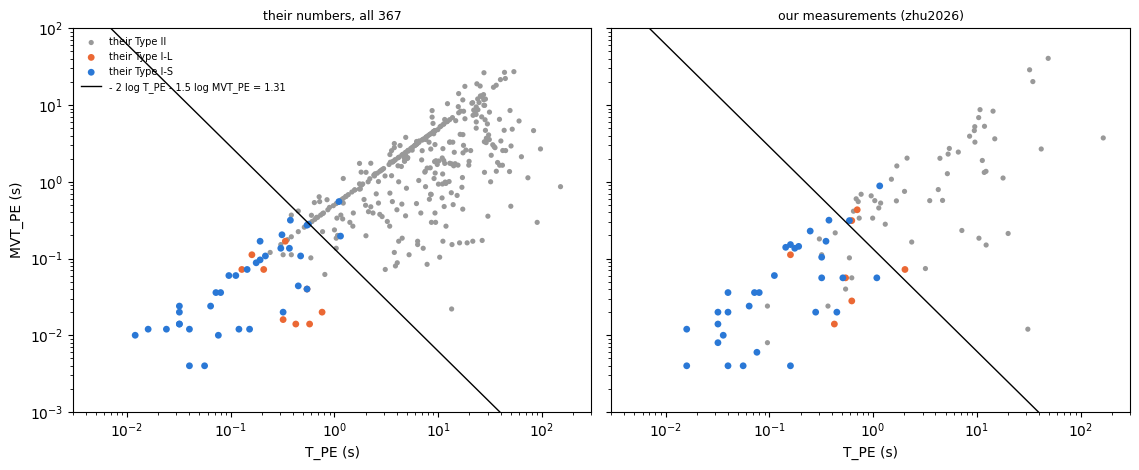

In [10]:
law2, c2 = best[("precursor timing", 2)]
(name_x, a_x), (name_y, a_y) = list(law2.items())
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharex=True, sharey=True)
for ax, (label, Xp, kinds) in zip(axes, [("their numbers, all 367", theirs, table.Type), ("our measurements (zhu2026)", X, ours.zhu_type)]):
    for kind in ("II", "I-L", "I-S"):
        sel = (kinds == kind).values
        ax.scatter(10 ** Xp[name_x][sel], 10 ** Xp[name_y][sel], s=14 if kind == "II" else 24, color=COLOURS[kind], edgecolor="none", label=f"their Type {kind}")
    xs = np.logspace(-2.5, 2.5, 50)
    ax.plot(xs, 10 ** ((c2 - a_x * np.log10(xs)) / a_y), color="k", lw=1.0, label=f"{L.describe(law2)} = {c2:.2f}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(f"{name_x} (s)"); ax.set_title(label, fontsize=9)
axes[0].set_ylabel(f"{name_y} (s)")
axes[0].set_xlim(3e-3, 300); axes[0].set_ylim(1e-3, 100)
axes[0].legend(frameon=False, fontsize=7, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "26_precursor_plane.png", dpi=140)
plt.show()

On their table the best law with the precursor's timing alone is -2 log T_PE - 1.5 log T_MVT,PE > 1.31 (nested balanced accuracy 0.93),
and with EPI's inputs -2 log T_PE + 2 log E_p,ME > 5.96 (0.97); EPI itself reaches 0.986 at 6.2 in sample. Applied unchanged to our
measurements, the laws keep a balanced accuracy of 0.85-0.97 whichever rule defines the episodes and however E_p,ME is fitted, so
they describe their classes robustly. None does better than EPI, and none needs the precursor's spectrum.

## 5. Each burst's chance under the laws

2000 draws of each burst's numbers within their errors (`features.input_draws`: the timing numbers move together as in one of its simulated light curves in which all of them were found, and each E_peak is drawn in log from its two profile errors), and the share of draws each law calls a merger. A burst missing a number a law needs, or whose number has no error, gets no chance under that law rather than a falsely certain one.

In [11]:
tests = {"EPI": (EPI_LAW, 6.2)}
for key in [("precursor timing", 2), ("precursor timing", 3), ("EPI's inputs", 3)]:
    tests[f"{key[0]}, {key[1]} terms"] = best[key]
draws = {name: input_draws(ours.loc[name], RESULTS / name) for name in ours.index}
chances = pd.DataFrame({name: L.probabilities(law, threshold, draws) for name, (law, threshold) in tests.items()})
chances["zhu_type"] = ours.zhu_type
settled = chances.drop(columns="zhu_type").apply(lambda p: ((p < 0.05) | (p > 0.95)).mean())
print("share of bursts settled (chance below 5% or above 95%):"); print(settled.round(2).to_string())
unsettled = chances[(chances.drop(columns="zhu_type") > 0.05).any(axis=1) & (chances.drop(columns="zhu_type") < 0.95).any(axis=1)]
print(len(unsettled), "bursts unsettled under at least one law")
unsettled.round(2).sort_values("EPI")

share of bursts settled (chance below 5% or above 95%):
EPI                          0.79
precursor timing, 2 terms    0.73
precursor timing, 3 terms    0.75
EPI's inputs, 3 terms        0.91
34 bursts unsettled under at least one law


,EPI,"precursor timing, 2 terms","precursor timing, 3 terms","EPI's inputs, 3 terms",zhu_type
110903B,0.00,0.80,0.80,0.00,II
181216A,0.00,0.08,0.03,0.00,II
180703B,0.00,0.00,1.00,0.03,II
180801B,0.00,0.25,0.11,0.00,II
201016A,0.00,0.00,0.05,0.00,II
241029A,0.00,0.10,0.08,0.00,II
131216A,0.03,0.39,0.10,0.02,II
090131A,0.03,0.85,0.80,0.00,II
140308B,0.04,0.20,0.23,0.00,II
141121B,0.05,0.24,0.24,0.02,II


Drawing each burst's numbers within their errors, EPI settles 79% of the bursts (chance below 5% or above 95%), the timing-only laws
73-75%, and the three-term law with E_p,ME 91%. 34 bursts are unsettled under at least one law, most of them their Type II
bursts near the line; the laws disagree mainly where T_MVT,PE decides.

## 6. The confirmed bursts

The only labels that don't come from a clustering. Too few to fit anything; a law that gets one of them wrong has a problem.

In [12]:
check = chances.loc[[n for n in L.CONFIRMED if n in chances.index]].copy()
check["confirmed"] = [L.CONFIRMED[n] for n in check.index]
check.round(2)

,EPI,"precursor timing, 2 terms","precursor timing, 3 terms","EPI's inputs, 3 terms",zhu_type,confirmed
211211A,1.00,1.0,1.0,1.0,I-L,merger
090618A,0.00,0.0,0.0,0.0,II,collapsar
180728A,0.00,0.0,0.0,0.0,II,collapsar
190114C,0.08,0.0,0.0,0.0,II,collapsar
190829A,0.00,0.0,0.0,0.0,II,collapsar
211023A,0.00,0.0,0.0,0.0,II,collapsar


Every law puts the confirmed bursts on the side their origin says: GRB 211211A a merger with chance 1.00 under all of them, the supernova
collapsars collapsars (chance 0.00, and 0.08 for 190114C under EPI). A handful of confirmed bursts can't test a law, but none of
them contradicts one.

### Sensitivity to the labels and to GBM's energy scale

Their types come from a clustering, and between EPI 6.0 and 6.4 they found both kinds, so those labels are the least certain. The search is run again with those bursts left out and with their labels flipped: a law that only holds with them as they are rests on doubtful labels. Then GBM's energy scale: its E_peak differs from GECAM's by about 10% in GRB 230307A's bright phase (notebook 15), which moves EPI by 2 log10(1.1) = 0.08.


In [13]:
from zhu.catalogue import EPI_UNSURE
their_epi = L.apply(EPI_LAW, theirs)
unsure = (their_epi > EPI_UNSURE[0]) & (their_epi < EPI_UNSURE[1])
print(f"{int(unsure.sum())} of their {len(theirs)} bursts have EPI between {EPI_UNSURE[0]} and {EPI_UNSURE[1]}:",
      ", ".join(f"{n} ({table.Type[n]})" for n in theirs.index[unsure]))
variants = {"their types": (theirs, y_theirs), "unsure band left out": (theirs[~unsure], y_theirs[~unsure]),
            "unsure band flipped": (theirs, y_theirs ^ unsure)}
rows = []
for variant, (Xv, yv) in variants.items():
    for label, cols, terms in (("precursor timing", L.PRECURSOR_TIMING, 2), ("EPI's inputs", L.EPI_INPUTS, 3)):
        top = L.search(Xv[cols], yv, max_terms=terms, top=1).iloc[0]
        rows.append(dict(labels=variant, inputs=label, terms=terms, law=top.text, threshold=top.threshold, auc_in_sample=top.auc))
pd.DataFrame(rows).round(3)


4 of their 367 bursts have EPI between 6.0 and 6.4: 090602A (II), 161001A (I-S), 200101A (II), 221203A (II)


,labels,inputs,terms,law,threshold,auc_in_sample
0,their types,precursor timing,2,- 2 log T_PE - 1.5 log MVT_PE,1.311,0.992
1,their types,EPI's inputs,3,- 1.5 log T_PE - 0.5 log T_QE1 + 1.5 log Ep_ME,4.009,1.000
2,unsure band left out,precursor timing,2,- 2 log T_PE - 1.5 log MVT_PE,1.311,0.994
3,unsure band left out,EPI's inputs,3,- 2 log T_PE - 1 log T_QE1 + 1.5 log Ep_ME,4.374,1.000
4,unsure band flipped,precursor timing,2,- 1.5 log T_PE - 2 log MVT_PE,1.477,0.990
5,unsure band flipped,EPI's inputs,3,- 1.5 log T_PE - 2 log MVT_PE + 2 log Ep_ME,6.680,0.999


In [14]:
has = ours.EPI_zhu.notna()
for scale in (0.9, 1.1):
    shift = 2 * np.log10(scale)
    moved = has & ((ours.EPI_zhu + shift > EPI_LINE) != (ours.EPI_zhu > EPI_LINE))
    print(f"E_p,ME x {scale}: EPI {shift:+.3f} dex; {int(moved.sum())} of {int(has.sum())} bursts change side of {EPI_LINE}:",
          ", ".join(f"{n} ({ours.zhu_type[n]}, EPI {ours.EPI_zhu[n]:.2f})" for n in ours.index[moved]) or "none")


E_p,ME x 0.9: EPI -0.092 dex; 0 of 95 bursts change side of 6.2: none
E_p,ME x 1.1: EPI +0.083 dex; 0 of 95 bursts change side of 6.2: none


Only 4 of their 367 bursts lie in the band where they found both types (090602A, 161001A, 200101A, 221203A). Leaving them out leaves the
best timing law unchanged; flipping their labels swaps its two exponents (-1.5 and -2) with almost the same area (0.990). The three-term
law with E_p,ME keeps E_p,ME and T_PE either way, but its exponents move and, with the labels flipped, its third term changes (T_MVT,PE
in place of the gap), so the data pin down its main terms, not its exact form. GBM's energy
scale doesn't matter here: E_p,ME 10% lower or higher moves EPI by 0.08-0.09 and takes none of the 95 bursts across 6.2.


### How many confirmed mergers would it take?

The two confirmed long mergers have precursors far softer than their main emission, but two bursts can't carry a test. If confirmed mergers really have log(E_p,PE/E_p,ME) like these two, with the scatter the candidates show, how many would a rank test against the supernova collapsars need? The answer depends on the assumed scatter and is a planning number, not a result.


In [15]:
from math import comb
from scipy.stats import ttest_ind
d = ours.assign(log_ratio=np.log10(ours.Ep_PE_ours / ours.Ep_ME_ours))
d = d[(d.measured_PE.astype(str) == "True") & (d.measured_ME.astype(str) == "True")]
kn = d[d.population == "confirmed merger (kilonova)"].log_ratio.dropna()
if kn_230307A is not None:
    kn = pd.concat([kn, pd.Series({"230307A (notebook 12's window)": np.log10(kn_230307A["ratio"])})])
sn = d[d.population == "collapsar (supernova)"].log_ratio.dropna()
scatter = d[d.population == "merger candidate"].log_ratio.std()
centre = kn.mean() if len(kn) else np.nan
print(f"confirmed mergers measured: {len(kn)} (mean log ratio {centre:.2f}); supernova collapsars measured: {len(sn)} "
      f"(mean {sn.mean():.2f}); scatter assumed {scatter:.2f} dex (the candidates')")
rng = np.random.default_rng(7)
rows = []
for n in (2, 3, 4, 6, 8, 12):
    for m in (len(sn), 10):
        # a rank test can't go below one over the number of orderings; Welch's t-test on log ratios drawn with the assumed scatter
        smallest_rank_p = 1 / comb(n + m, n)
        power = np.mean([ttest_ind(rng.normal(centre, scatter, n), rng.normal(sn.mean(), scatter, m), equal_var=False,
                                   alternative="less").pvalue < 0.05 for _ in range(2000)])
        rows.append(dict(confirmed_mergers=n, supernova_collapsars=m, smallest_rank_test_p=smallest_rank_p, welch_power=power))
pd.DataFrame(rows).round(3)


confirmed mergers measured: 2 (mean log ratio -1.02); supernova collapsars measured: 2 (mean -0.05); scatter assumed 0.44 dex (the candidates')


,confirmed_mergers,supernova_collapsars,smallest_rank_test_p,welch_power
0,2,2,0.167,0.270
1,2,10,0.015,0.563
2,3,2,0.100,0.458
3,3,10,0.003,0.812
4,4,2,0.067,0.523
5,4,10,0.001,0.932
6,6,2,0.036,0.558
7,6,10,0.000,0.988
8,8,2,0.022,0.554
9,8,10,0.000,0.998


The two confirmed long mergers' precursors are much softer than their main emissions (mean log ratio -1.02, a factor of 10), the
measured supernova collapsars' about as hard as theirs (-0.05). With so few, no rank test can reach 5%: with two of each the
smallest p possible is 1/6. If confirmed mergers really sit there, with the candidates' scatter (0.44 dex), about four confirmed mergers
against ten supernova collapsars with a measured ratio would give a 90% chance of a 5% result (Welch's test); with only the two such
collapsars there are now, more mergers alone wouldn't, since the power stays below 0.56. That is a planning number for when more kilonovae
and supernovae are found, not a result.


## 7. What the laws mean physically

**Measured.** On their 367 bursts the precursor's duration alone separates their types almost as well as EPI does (area 0.986 against
0.9998), and in every law that does well T100,PE carries the largest weight, with an exponent of -1.5 to -2: their Type I precursors are
short. Adding how fast the precursor varies (T_MVT,PE, exponent -1.5) or the gap after it brings a timing-only law close to EPI, and
E_p,ME closes the rest. None of the laws needs the precursor's spectrum.

**Interpretation.** A merger candidate's precursor is short and varies quickly, and a hard main emission follows within seconds. A
precursor of a fraction of a second fits models in which it comes from the last moments before the merger: a neutron star's crust
shattered by a tidal resonance, or the two magnetospheres interacting, with the main emission once the remnant launches a jet. A
collapsar's precursor can last tens of seconds (GRB 090618's first episode is 35 s), more like the time the jet takes to work its way out
of the star. That is only a reading of the classification, which is itself built from these numbers: the laws describe Zhu et al.'s
classes, and whether the classes are mergers and collapsars is what only the confirmed bursts can test (section 6).

## 8. What this says

**Measured.** On our own numbers, neither the precursor's E_peak nor its ratio to the main emission adds anything to EPI or to its four
inputs (permutation p from 0.3 to 0.7), however the limits are placed, without the least certain labels, and at either end of GBM's energy
scale: the precursor's hardness follows the main emission's. The compact laws found on their table are led by the precursor's duration
and describe their classes robustly on our measurements, but none does better than EPI. The two confirmed long mergers have precursors far
softer than their main emission (0.05 and 0.19, against 0.91 for the supernova collapsars), but two bursts can't carry a test.

**So** the answer to the project's spectral question is null: the precursor's E_peak doesn't add to Zhu et al.'s classification. What is
left open is whether the soft precursors of confirmed mergers are typical of mergers, which needs more confirmed events (about four
against ten collapsars for a 90% chance of a significant result).